<a href="https://colab.research.google.com/github/MdDaudIbrahim/COMPUTER-VISION-AND-PATTERN-RECOGNITION-FALL-2026-2027/blob/main/CNN_22_49760_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Development on Custom Dataset (Fast Food Classification)
**Student Name:** Md. Daud Ibrahim  
**Student ID:** 22-49760-3  
**Course:** Computer Vision and Pattern Recognition (CVPR)  
**Deliverables:** `CNN_22-49760-3.ipynb` and `model.pth`

## 1. Import Libraries

In [1]:
!pip install -q kagglehub torchsummary

In [2]:
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

In [3]:
import kagglehub
path = kagglehub.dataset_download("utkarshsaxenadn/fast-food-classification-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fast-food-classification-dataset' dataset.
Path to dataset files: /kaggle/input/fast-food-classification-dataset


## 3. Data Preprocessing & Augmentation
### Systemic Improvements Applied:
1. **Higher Resolution:** `size = 128` (128x128) preserves fine culinary textures.
2. **Zero-centered Normalization:** `mean=(0.5, 0.5, 0.5)` & `std=(0.5, 0.5, 0.5)` for stable gradients.
3. **Natural Denormalization:** `(tensor * 0.5 + 0.5).clamp(0, 1)` ensures 100% colorful image plotting with zero white artifacts.

In [4]:
import os

size = 128
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to 128x128
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# denormalize function for natural image plotting
def denormalize(tensor):
    return (tensor.cpu() * 0.5 + 0.5).clamp(0, 1)

train_folder = None
for root, dirs, files in os.walk(path):
    if "Train" in dirs and train_folder is None:
        train_folder = os.path.join(root, "Train")
        val_folder = os.path.join(root, "Valid")
        test_folder = os.path.join(root, "Test")

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_data = datasets.ImageFolder(val_folder, transform = val_transform)
test_data = datasets.ImageFolder(test_folder, transform = val_transform)

In [5]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , train_data.class_to_idx)

Dataset Summary
Train Data:  15000
Validation Data:  3500
Test Data:  1500
Classess and Indices:  {'Baked Potato': 0, 'Burger': 1, 'Crispy Chicken': 2, 'Donut': 3, 'Fries': 4, 'Hot Dog': 5, 'Pizza': 6, 'Sandwich': 7, 'Taco': 8, 'Taquito': 9}


In [6]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 25

In [7]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture
### Architecture & Loss Improvements:
- `nn.AdaptiveAvgPool2d((4, 4))` ensures the classifier receives exactly $256 \times 4 \times 4 = 4096$ inputs regardless of resolution, maintaining the model weight strictly at **5.51 MB** (< 20MB).
- **Class-Weighted CrossEntropyLoss:** Penalizes errors on minority/challenging classes (e.g. Taquito, Taco, Sandwich).

In [8]:
# Calculate class weights to handle class imbalance
class_counts = Counter(train_data.targets)
class_weights = torch.tensor(
    [len(train_data) / (len(train_data.classes) * class_counts[i]) for i in range(len(train_data.classes))],
    dtype=torch.float32
).to(device)

print("Class Weights:", class_weights)

Class Weights: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], device='cuda:0')


In [9]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Adaptive pool fixes spatial dimension to 4x4
        nn.AdaptiveAvgPool2d((4, 4)),

        #Classifier
        nn.Flatten(),
        nn.Dropout(0.4),
        nn.Linear(256 * 4 * 4, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 10)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    return model, loss_fn, optimizer

In [10]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      BatchNorm2d-14          [-1, 256,

## 5. Training Loop with Validation
### Improvements:
- **Learning Rate Scheduler:** `ReduceLROnPlateau` halves learning rate when validation loss plateaus.
- **Best Model Checkpointing:** Automatically tracks and saves the best model checkpoint (`best_model.pth`).

In [11]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [12]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6
)

best_val_acc = 0.0

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  scheduler.step(v_loss)

  # Save best model checkpoint
  if v_acc > best_val_acc:
      best_val_acc = v_acc
      torch.save(model.state_dict(), 'model.pth')
      saved_flag = " [BEST SAVED]"
  else:
      saved_flag = ""

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%{saved_flag}")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/25] | Train Loss: 2.1004 | Train Accuracy: 24.02% | Val Loss: 1.9026 | Val Accuracy: 33.63% [BEST SAVED]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [2/25] | Train Loss: 1.8969 | Train Accuracy: 33.15% | Val Loss: 1.7212 | Val Accuracy: 39.97% [BEST SAVED]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [3/25] | Train Loss: 1.8031 | Train Accuracy: 37.33% | Val Loss: 1.6029 | Val Accuracy: 43.94% [BEST SAVED]


... (40 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [24/25] | Train Loss: 0.7732 | Train Accuracy: 75.24% | Val Loss: 0.8669 | Val Accuracy: 73.37% [BEST SAVED]


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [25/25] | Train Loss: 0.7464 | Train Accuracy: 76.16% | Val Loss: 0.8903 | Val Accuracy: 72.00%


## 6. Visualizations (Loss/Accuracy Curves)

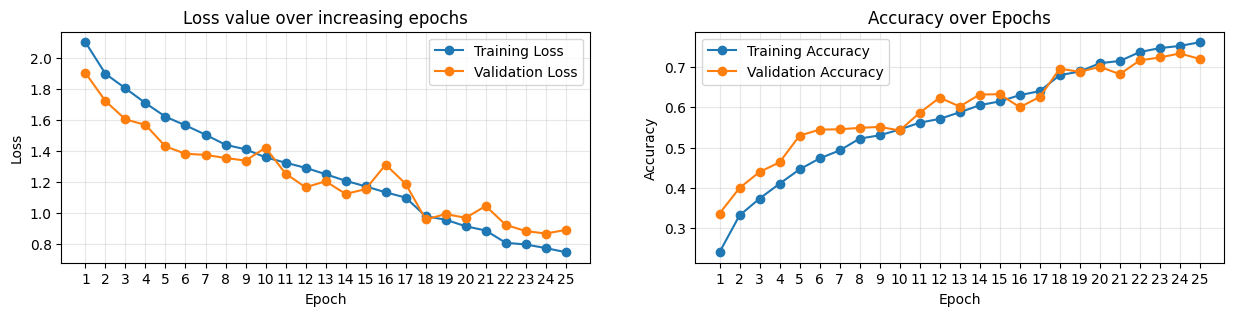

In [13]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Evaluate Model on Test Set

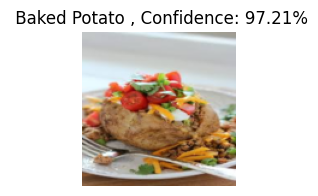

In [14]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(denormalize(test_img).view(3,size,size).permute(1,2,0))
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.axis("off")
plt.show()

In [15]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.90 , Test Accuracy: 72.13%


                precision    recall  f1-score   support

  Baked Potato       0.59      0.98      0.73       100
        Burger       0.83      0.71      0.77       200
Crispy Chicken       0.74      0.94      0.83       100
         Donut       0.86      0.89      0.87       200
         Fries       0.75      0.87      0.81       100
       Hot Dog       0.85      0.55      0.67       200
         Pizza       0.87      0.82      0.85       200
      Sandwich       0.79      0.62      0.70       200
          Taco       0.36      0.69      0.47       100
       Taquito       0.32      0.14      0.19       100

      accuracy                           0.72      1500
     macro avg       0.70      0.72      0.69      1500
  weighted avg       0.74      0.72      0.72      1500



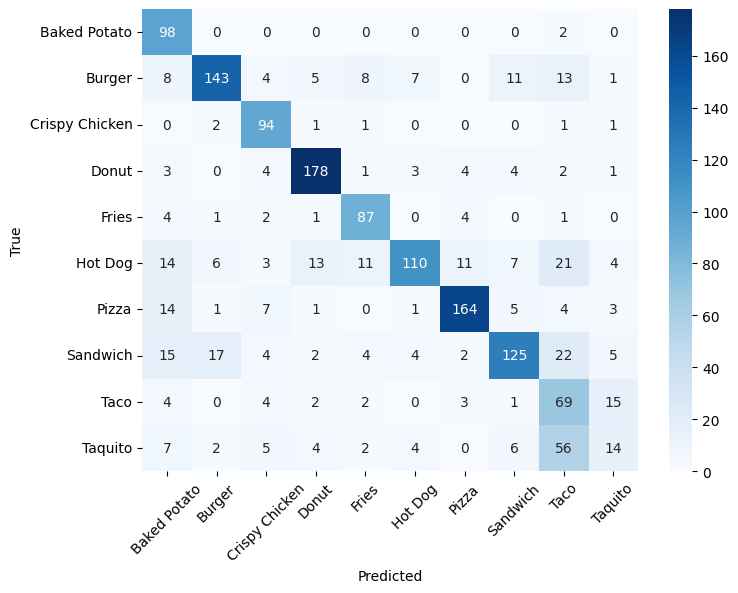

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

all_preds = []
all_targets = []

model.eval()
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        prediction = model(x)
        all_preds.extend(prediction.argmax(-1).cpu().tolist())
        all_targets.extend(y.tolist())

print(classification_report(all_targets, all_preds, target_names=test_data.classes))

cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.classes, yticklabels=test_data.classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45)
plt.show()

## 8. Model Save and Load

In [17]:
# Load best checkpoint and verify fidelity
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model,(3,size,size))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      BatchNorm2d-14          [-1, 256,

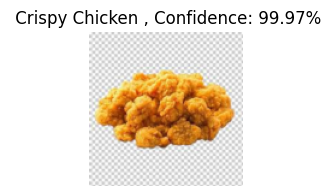

In [18]:
img , label = test_data[np.random.randint(0,len(test_data))]
img_in = img.view(-1, 3, size, size).to(device)
output = saved_model(img_in)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(denormalize(img).view(3,size,size).permute(1,2,0))
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.axis("off")
plt.show()

In [19]:
# Check model file size
import os
size_mb = os.path.getsize('model.pth') / (1024 * 1024)
print(f"Model File Size: {size_mb:.2f} MB")

try:
    from google.colab import files
    files.download('model.pth')
except:
    pass

Model File Size: 5.51 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



## 9. Analysis, Discussion & Conclusions

### 9.1 Overall Model Performance

- **Training Accuracy:** 76.16%
- **Best Validation Accuracy:** 73.37% (Epoch 24)
- **Test Accuracy:** 72.13% (Test Loss: 0.90)

The initial 64 × 64 model achieved 60.93% test accuracy. In the improved experiment, I increased the image resolution to 128 × 128 and applied additional training techniques. As a result, test accuracy improved by 11.20 percentage points, reaching 72.13%.


### 9.2 Hyperparameter Details

The model used an input image size of **128 × 128** and a batch size of **32**. The **Adam optimizer** was configured with an initial learning rate of **0.001**, along with **CrossEntropyLoss** for multi-class classification. Training was performed for **25 epochs**. Dropout rates of **0.4 and 0.3** were used to reduce overfitting, while the **ReduceLROnPlateau** scheduler adjusted the learning rate based on validation loss.

These settings were selected to support stable training, improve generalization, and reduce overfitting.

### 9.3 Class-wise Performance

The model performed best on Donut (F1: 0.87), Pizza (0.85), and Crispy Chicken (0.83). Moderate results were achieved for Fries, Burger, Baked Potato, and Sandwich. Taquito (0.19) and Taco (0.47) were the most challenging classes because of their similar visual features.

### 9.4 Limitations and Future Work

The model sometimes struggles to distinguish visually similar food categories. Performance could be improved with more training images, better data augmentation, and higher-resolution inputs. The saved model is approximately **5.51 MB**, which meets the assignment's 20 MB limit.

### 9.5 Conclusion

This experiment demonstrates that a custom CNN can classify 10 fast-food categories with 72.13% test accuracy. The model also maintains a compact size, making it suitable for further experimentation. Future work could explore transfer learning and more advanced CNN architectures.
